In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os, urllib.request, zipfile

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
np.random.seed(0)

Using device: cuda


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
base = '/content/drive/MyDrive/Malabar_Dataset'

train_dir = os.path.join(base, "train")
val_dir = os.path.join(base, "validation")

print("Dataset folder:", base)
print("train:", os.listdir(train_dir))
print("val:", os.listdir(val_dir))

Dataset folder: /content/drive/MyDrive/Malabar_Dataset
train: ['Downy-Mildew', 'Health-Leaf', 'Bacterial-Spot', 'Anthracnose', 'Pest-Damage']
val: ['Anthracnose', 'Bacterial-Spot', 'Pest-Damage', 'Downy-Mildew', 'Health-Leaf']


In [6]:
IMG_SIZE = 128
BATCH_SIZE = 32

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

train_ds = datasets.ImageFolder(
    train_dir, transform=basic_transform
)

val_ds = datasets.ImageFolder(
    val_dir, transform=basic_transform
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False
)

print("Classes:", train_ds.classes)
print("Train images:", len(train_ds))
print("Val images:", len(val_ds))

Classes: ['Anthracnose', 'Bacterial-Spot', 'Downy-Mildew', 'Health-Leaf', 'Pest-Damage']
Train images: 2405
Val images: 601


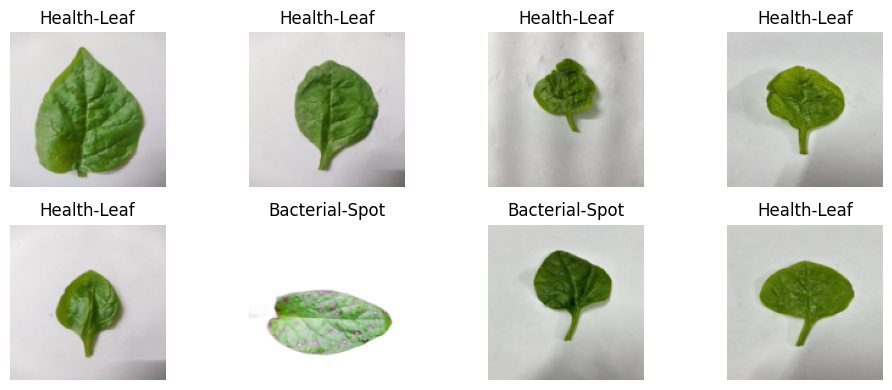

In [7]:
images, labels = next(iter(train_loader))
class_names = train_ds.classes

plt.figure(figsize=(10, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Feature Extractor
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # ANN Classifier
        self.fc1 = nn.Linear(64 * 16 * 16, 128)

        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):

        # Convolution Block 1
        x = self.pool(F.relu(self.conv1(x)))

        # Convolution Block 2
        x = self.pool(F.relu(self.conv2(x)))

        # Convolution Block 3
        x = self.pool(F.relu(self.conv3(x)))

        # Flatten
        x = torch.flatten(x, 1)

        # ANN Classifier
        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


model = SimpleCNN().to(device)

print(model)

n_params = sum(p.numel() for p in model.parameters())

print(f"\nTotal trainable parameters: {n_params:,}")

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=5, bias=True)
)

Total trainable parameters: 2,121,509


In [10]:
def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        # TRAINING
        model.train()

        running_loss, correct, total = 0.0, 0, 0

        for imgs, labels in train_loader:

            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(imgs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * imgs.size(0)

            correct += (outputs.argmax(1) == labels).sum().item()

            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # VALIDATION
        model.eval()

        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():

            for imgs, labels in val_loader:

                imgs, labels = imgs.to(device), labels.to(device)

                outputs = model(imgs)

                loss = criterion(outputs, labels)

                running_loss += loss.item() * imgs.size(0)

                correct += (outputs.argmax(1) == labels).sum().item()

                total += labels.size(0)

        val_loss = running_loss / total
        val_acc = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:2d}/{epochs}  "
              f"train_loss={train_loss:.3f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    return history


history_plain = train_model(
    model, train_loader, val_loader, epochs=15
)

Epoch  1/15  train_loss=1.318 train_acc=0.469 | val_loss=1.296 val_acc=0.453
Epoch  2/15  train_loss=1.210 train_acc=0.519 | val_loss=1.339 val_acc=0.519
Epoch  3/15  train_loss=1.131 train_acc=0.543 | val_loss=1.317 val_acc=0.449
Epoch  4/15  train_loss=1.066 train_acc=0.569 | val_loss=1.281 val_acc=0.529
Epoch  5/15  train_loss=1.009 train_acc=0.596 | val_loss=1.272 val_acc=0.494
Epoch  6/15  train_loss=0.961 train_acc=0.618 | val_loss=1.341 val_acc=0.522
Epoch  7/15  train_loss=0.915 train_acc=0.635 | val_loss=1.363 val_acc=0.516
Epoch  8/15  train_loss=0.868 train_acc=0.665 | val_loss=1.397 val_acc=0.489
Epoch  9/15  train_loss=0.826 train_acc=0.677 | val_loss=1.476 val_acc=0.514
Epoch 10/15  train_loss=0.787 train_acc=0.683 | val_loss=1.717 val_acc=0.471
Epoch 11/15  train_loss=0.742 train_acc=0.707 | val_loss=1.636 val_acc=0.461
Epoch 12/15  train_loss=0.666 train_acc=0.751 | val_loss=1.986 val_acc=0.504
Epoch 13/15  train_loss=0.601 train_acc=0.767 | val_loss=2.007 val_acc=0.489

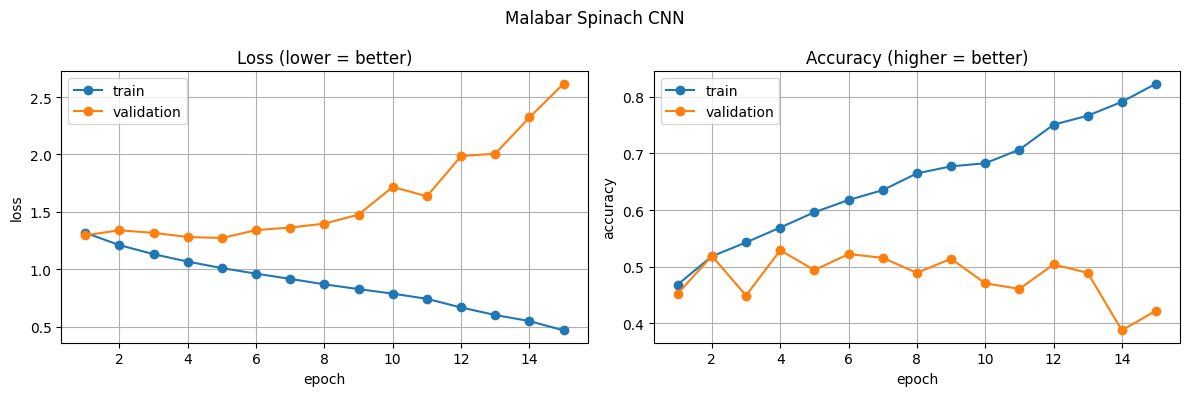

In [11]:
def plot_history(history, title=""):

    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_loss"], "o-", label="train")

    ax1.plot(epochs, history["val_loss"], "o-", label="validation")

    ax1.set_title("Loss (lower = better)")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("loss")
    ax1.legend()
    ax1.grid(True)

    ax2.plot(epochs, history["train_acc"], "o-", label="train")

    ax2.plot(epochs, history["val_acc"], "o-", label="validation")

    ax2.set_title("Accuracy (higher = better)")
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("accuracy")
    ax2.legend()
    ax2.grid(True)

    fig.suptitle(title)

    plt.tight_layout()
    plt.show()


plot_history(history_plain, "Malabar Spinach CNN")

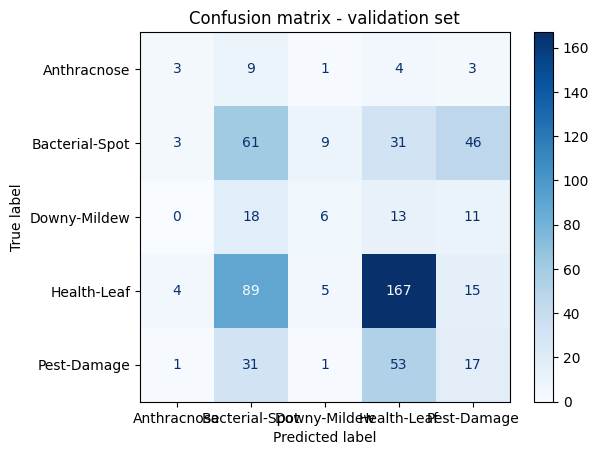

                precision    recall  f1-score   support

   Anthracnose       0.27      0.15      0.19        20
Bacterial-Spot       0.29      0.41      0.34       150
  Downy-Mildew       0.27      0.12      0.17        48
   Health-Leaf       0.62      0.60      0.61       280
   Pest-Damage       0.18      0.17      0.17       103

      accuracy                           0.42       601
     macro avg       0.33      0.29      0.30       601
  weighted avg       0.43      0.42      0.42       601



In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def get_predictions(model, loader):

    model.eval()

    preds, targets = [], []

    with torch.no_grad():

        for imgs, labels in loader:

            outputs = model(imgs.to(device))

            preds.append(outputs.argmax(1).cpu())

            targets.append(labels)

    return torch.cat(preds).numpy(), torch.cat(targets).numpy()


y_pred, y_true = get_predictions(model, val_loader)

class_names = val_ds.classes

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion matrix - validation set")
plt.show()

print(classification_report(
    y_true, y_pred, target_names=class_names
))